# 1. 일별 주문량 만들기

Olist 주문 데이터로 일별 주문량을 예측

- 데이터: Olist Brazilian E-Commerce (Kaggle), `orders` 테이블
- 도구: SQLite(쿼리는 DB 툴에서 실행), Python(pandas, matplotlib)

## 1-1. 데이터 불러오기

In [2]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/Users/gon-i/Desktop/olist.db')

tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn)
print(tables)

                   name
0             customers
1           geolocation
2           order_items
3        order_payments
4         order_reviews
5                orders
6              products
7               sellers
8  category_translation
9             geo_clean


- `orders` 99,441건, 원본 그대로 사용
- 이전 배송 지연 분석에서는 도착일 오류 주문 282건을 제외했지만, 이번엔 구매일 기준이라 영향 없음

## 1-2. 기준 정하기

**날짜 기준**: `order_purchase_timestamp`(구매 시각)
- 주문이 처음 들어온 시점이 입고 물량의 출발점이라고 판단

**주문 상태 기준**: 취소 포함 전체 주문

| order_status | 건수 |
|---|---|
| delivered | 96,478 |
| shipped | 1,107 |
| canceled | 625 |
| unavailable | 609 |
| invoiced | 314 |
| processing | 301 |
| created | 5 |
| approved | 2 |

- 수요 예측이 목적이라 취소된 주문도 고객이 주문을 넣은 양으로 보고 전체 사용
- 취소 비율(canceled + unavailable 1,234건, 약 1.2%)은 따로 계산해두고, 나중에 처리 물량을 추정할 때 활용

## 1-3. 일별 주문 수

날짜별 합계 99,441건으로 전체 주문 수와 일치 확인

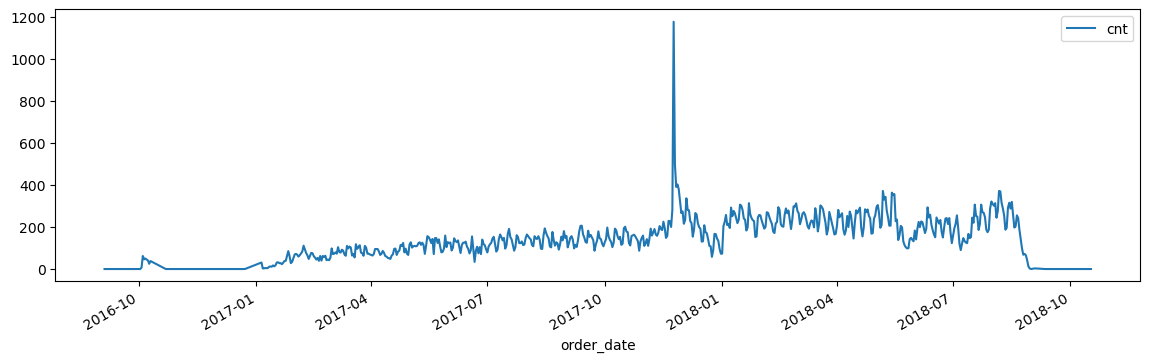

In [4]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect('/Users/gon-i/Desktop/olist.db')

query = """
SELECT DATE(order_purchase_timestamp) AS order_date,
       COUNT(*) AS cnt
FROM orders
GROUP BY order_date
"""
daily = pd.read_sql(query, conn)
conn.close()

daily['order_date'] = pd.to_datetime(daily['order_date'])

daily.plot(x='order_date', y='cnt', figsize=(14, 4))
plt.show()

- 2016년: 하루 1건 수준이거나 주문 없는 날이 이어짐 (11 ~ 12월 직선은 빈 날짜를 점끼리 이은 것)
- 2017년부터 꾸준히 증가
- 2017년 11월 말 1,200건 가까이 튀는 날 하나
- 2018년 8월 말부터 급감, 9월 이후 거의 0

## 1-4. 분석 기간

**시작: 2017년부터**
- 2016년은 주문이 띄엄띄엄 있어 데이터가 제대로 쌓이기 전 구간으로 판단

**끝: 2018-08-21**
- 처음엔 8월 31일까지 넣어서 감소하는 모습도 보여줘야 하나 고민함
- 그런데 9 ~ 10월은 하루 1건, 그마저 날짜가 비어 있음. 수요가 줄었다면 줄어든 수준으로라도 주문이 이어져야 하는데 그렇지 않아서 데이터 수집이 끝나가는 구간으로 판단
- 주말엔 원래 적어서 같은 요일끼리 비교

| 요일 | 2주 전 | 1주 전 | 해당 주 |
|---|---|---|---|
| 월 | 08-06: 372 | 08-13: 292 | 08-20: 256 |
| 화 | 08-07: 370 | 08-14: 316 | 08-21: 243 |
| 수 | 08-08: 316 | 08-15: 288 | 08-22: 187 |
| 목 | 08-09: 289 | 08-16: 320 | 08-23: 144 |

- 8/22(수)부터 같은 요일 평소보다 약 35% 낮아서 그 전날을 끝점으로 결정
- 제외된 주문 1,051건 (1.06%)

## 1-5. 빠진 날짜

- 2017-01-01 ~ 2018-08-21은 598일인데 주문이 있는 날은 594일, 4일이 빔

In [7]:
pd.date_range(start = "2017-01-01", end = "2018-08-21")

DatetimeIndex(['2017-01-01', '2017-01-02', '2017-01-03', '2017-01-04',
               '2017-01-05', '2017-01-06', '2017-01-07', '2017-01-08',
               '2017-01-09', '2017-01-10',
               ...
               '2018-08-12', '2018-08-13', '2018-08-14', '2018-08-15',
               '2018-08-16', '2018-08-17', '2018-08-18', '2018-08-19',
               '2018-08-20', '2018-08-21'],
              dtype='datetime64[ns]', length=598, freq='D')

In [8]:
full_range = pd.date_range(start='2017-01-01', end='2018-08-21', freq='D')

daily['order_date'] = pd.to_datetime(daily['order_date'])

missing_days = full_range.difference(daily['order_date'])

print(len(missing_days))
print(missing_days)

4
DatetimeIndex(['2017-01-01', '2017-01-02', '2017-01-03', '2017-01-04'], dtype='datetime64[ns]', freq='D')


- 빠진 4일은 2017-01-01 ~ 01-04, 전부 기간 맨 앞
- 중간에 흩어져 있었으면 0으로 채웠겠지만, 맨 앞에 몰려 있어 새해 연휴와 서비스 초기 구간으로 판단
- 0으로 채우면 시작하자마자 4일 연속 주문이 없다는 패턴이 생겨서 **시작일을 2017-01-05로 변경**
- 변경 후 594일 모두 주문 있음, 제외 주문 수는 그대로

## 1-6. 튀는 날, 적은 날

**최대: 2017-11-24 (금) 1,176건, 블랙프라이데이**

| 날짜 | 주문 수 |
|---|---|
| 11-13 ~ 11-21 | 205 ~ 230 |
| 11-24 | 1,176 |
| 11-25 ~ 11-29 | 499, 391, 403, 380, 323 |
| 11-30 | 267 |

- 오류가 아니라 실제로 주문이 몰린 날이라 삭제하지 않음
- 당일뿐 아니라 이후 5일도 평소의 1.5 ~ 2배
- 모델이 이 날 때문에 주변까지 높게 예측하지 않도록 표시 컬럼을 따로 두기로 함
  - `event_peak`: 11/24
  - `event_after`: 11/25 ~ 11/29

**최소: 2017-01-06, 01-07, 각 4건**
- 이후 끊기지 않고 서서히 늘어나서 데이터 문제가 아닌 실제 성장 구간으로 보고 유지
- 갑자기 끊기거나 빈 구간은 자르고, 서서히 변하는 구간은 남기는 기준으로 판단